# No-Show Predictor: прогноз неявки клиента барбершопа

## 1.1 Бизнес-постановка

Барбершоп теряет выручку и рабочее время мастера, когда клиент записывается,
но не приходит на визит (no-show). Администратор вынужден либо звонить всем подряд
(тратит время), либо оставлять свободное окно в расписании (теряет деньги).

**Цель бизнеса:** заранее, минимум за 24 часа до визита, оценивать риск неявки
каждой записи, чтобы администратор мог:
- точечно позвонить именно «рискованным» клиентам и подтвердить визит;
- при высоком риске заранее предложить слот клиентам из листа ожидания;
- эффективнее планировать загрузку мастеров.

Ключевая метрика бизнеса — снижение доли неявок при сохранении загрузки,
однако сначала нужно научиться эти неявки предсказывать, чему и посвящён проект.

## 1.2 Постановка ML-задачи

- **Тип задачи:** бинарная классификация с учителем.
- **Целевая переменная `no_show`:** 1 — клиент не пришёл, 0 — пришёл.
- **Момент прогноза:** строго за 24 часа до визита. Все признаки, которые
  становятся известны позже (факт визита, отмена после прогноза), использовать
  нельзя — это приведёт к утечке данных (data leakage).
- **Объект:** одна запись клиента к мастеру.
- **Целевая функция на инференсе:** вероятность неявки `P(no_show = 1 | X)`,
  порог бинаризации будет выбран отдельно с учётом стоимости ошибок.

## 1.3 Набор данных

Реальной выгрузки CRM в открытом доступе нет, поэтому ниже генерируется
**синтетический датасет** (~6000 записей, фиксированный `random_state`).
Он воспроизводим и подходит для демонстрации пайплайна EDA, но **не является
доказательством того, как ведут себя реальные клиенты барбершопа**. В признаки
заложены правдоподобные зависимости:

- профиль клиента: возраст, пол, история визитов, прошлые неявки и отмены, средний чек;
- параметры визита: тип услуги, длительность, цена, мастер, канал записи;
- календарные признаки: день недели, час, месяц, признак выходного дня;
- коммуникация: факт отправки напоминания и за сколько часов оно ушло.

Полного набора признаков достаточно для постановки задачи бинарной классификации
и проверки нескольких гипотез о причинах неявок.

## 1.4 Метрика качества и её обоснование

Классы несбалансированы (неявок заметно меньше, чем визитов), поэтому
**Accuracy не подходит** — модель, всегда предсказывающая «пришёл», получит
высокую точность, но будет бесполезна для бизнеса.

Выбираем **набор метрик**:

- **ROC-AUC** — общая разделяющая способность модели; устойчива к дисбалансу
  классов и не зависит от выбора порога, удобна для сравнения моделей.
- **Average Precision (PR-AUC)** — при сильном дисбалансе показывает качество
  именно на «редком» классе неявок, не раздувается за счёт легко предсказуемых
  отрицательных примеров.
- **Precision / Recall класса 1** и матрица ошибок — для итогового выбора порога.
  В бизнес-логике **False Negative (пропущенная неявка) дороже**, чем
  **False Positive (лишний звонок администратора)**: один звонок стоит минуты,
  а пустое окно — реальных денег. Поэтому финальный порог будем смещать
  в сторону более высокого Recall при приемлемом Precision.

## 1.5 Что делаем в этом ноутбуке

Ниже — разведочный анализ данных (EDA): первичная проверка, распределение
целевой переменной, анализ временных, клиентских и категориальных признаков,
выбросы и корреляции. Цель EDA — понять структуру данных, найти проблемы,
выбрать предобработку и сформулировать гипотезы для будущей модели.

In [ ]:
# ДЛЯ ПЕРВОГО ЗАПУСКА 
#%pip install numpy pandas seaborn matplotlib
# ДЛЯ ПЕРВОГО ЗАПУСКА
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_STATE = 42
N_ROWS = 6000

rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 40)

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl (12.6 MB)
Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl (9.7 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.11.2-cp312-cp312-

## 2. Генерация демонстрационного датасета

Данные генерируются с фиксированным seed, поэтому результаты воспроизводимы.
Вероятность неявки зависит от нескольких заранее заданных факторов: первого визита,
предыдущих неявок, канала записи, времени визита и напоминания.
Это искусственно заданные зависимости, а не выводы из реальных данных.

In [4]:
# Сначала создаём клиентов и историю, которая известна до текущей записи.
client_id = rng.integers(1, 1201, size=N_ROWS)
is_first_visit = rng.choice([1, 0], size=N_ROWS, p=[0.25, 0.75]).astype(bool)

visits_total = np.where(is_first_visit, 0, rng.poisson(6, size=N_ROWS))
visits_last_90d = np.where(
    is_first_visit, 0, np.minimum(rng.poisson(2, size=N_ROWS), visits_total)
)
last_visit_days_ago = np.where(
    is_first_visit, np.nan, np.clip(rng.exponential(60, size=N_ROWS), 1, 500)
)

# Исторические показатели трактуются как информация ДО текущей записи.
no_show_total = np.where(is_first_visit, 0, rng.poisson(0.5, size=N_ROWS))
cancel_total = np.where(is_first_visit, 0, rng.poisson(0.6, size=N_ROWS))

client_age = np.clip(rng.normal(32, 9, size=N_ROWS), 18, 70).astype(int)
client_gender = rng.choice(["М", "Ж"], size=N_ROWS, p=[0.75, 0.25])
avg_check = np.clip(rng.normal(2200, 500, size=N_ROWS), 800, 5000).round(0)

service_type = rng.choice(
    ["Стрижка", "Борода", "Комплекс", "Детская стрижка", "Укладка"],
    size=N_ROWS,
    p=[0.45, 0.20, 0.20, 0.10, 0.05],
)
service_prices = {
    "Стрижка": 1800,
    "Борода": 1200,
    "Комплекс": 2800,
    "Детская стрижка": 1400,
    "Укладка": 1000,
}
service_durations = {
    "Стрижка": 45,
    "Борода": 30,
    "Комплекс": 75,
    "Детская стрижка": 30,
    "Укладка": 30,
}
duration_min = np.array([service_durations[s] for s in service_type])
price = np.array([service_prices[s] for s in service_type])
price = (price * rng.uniform(0.9, 1.1, size=N_ROWS)).round(0)

channel = rng.choice(["Онлайн", "Телефон"], size=N_ROWS, p=[0.65, 0.35])
master_id = rng.integers(1, 9, size=N_ROWS)

# Записи распределены по всему 2025 году, только в рабочие часы 10:00–21:00.
days = pd.to_datetime("2025-01-01") + pd.to_timedelta(
    rng.integers(0, 365, size=N_ROWS), unit="D"
)
hour = rng.integers(10, 22, size=N_ROWS)
appointment_datetime = days.normalize() + pd.to_timedelta(hour, unit="h")
day_of_week = appointment_datetime.dayofweek
month = appointment_datetime.month
is_weekend = day_of_week >= 5

# Напоминание отправляется до момента прогнозирования (не позже чем за 24 часа).
reminder_sent = rng.choice([True, False], size=N_ROWS, p=[0.70, 0.30])
reminder_hours_before = np.where(
    reminder_sent, rng.choice([24, 36, 48], size=N_ROWS), np.nan
)

# Искусственно задаём вероятность неявки.
# Коэффициенты выбраны для демонстрации, а не оценены на реальных данных.
logit = (
    -2.35
    + 0.65 * is_first_visit
    + 0.45 * (channel == "Онлайн")
    + 0.55 * (hour <= 11)
    + 0.40 * (hour >= 20)
    + 0.20 * is_weekend
    + 0.35 * (no_show_total >= 2)
    - 0.30 * (visits_total >= 5)
    - 0.25 * reminder_sent
    + 0.10 * (client_age < 25)
    + rng.normal(0, 0.35, size=N_ROWS)
)
prob_no_show = 1 / (1 + np.exp(-logit))
no_show = rng.binomial(1, prob_no_show, size=N_ROWS)

df = pd.DataFrame({
    "appointment_id": np.arange(1, N_ROWS + 1),
    "client_id": client_id,
    "appointment_datetime": appointment_datetime,
    "master_id": master_id,
    "service_type": service_type,
    "duration_min": duration_min,
    "price": price,
    "channel": channel,
    "is_first_visit": is_first_visit,
    "client_age": client_age,
    "client_gender": client_gender,
    "visits_total": visits_total,
    "visits_last_90d": visits_last_90d,
    "last_visit_days_ago": last_visit_days_ago,
    "no_show_total": no_show_total,
    "cancel_total": cancel_total,
    "avg_check": avg_check,
    "reminder_sent": reminder_sent,
    "reminder_hours_before": reminder_hours_before,
    "day_of_week": day_of_week,
    "hour": hour,
    "month": month,
    "is_weekend": is_weekend,
    "no_show": no_show,
})

df.head()

,appointment_id,client_id,appointment_datetime,master_id,service_type,duration_min,price,channel,is_first_visit,client_age,client_gender,visits_total,visits_last_90d,last_visit_days_ago,no_show_total,cancel_total,avg_check,reminder_sent,reminder_hours_before,day_of_week,hour,month,is_weekend,no_show
0,1,108,2025-05-08 21:00:00,6,Стрижка,45,1823.0,Онлайн,False,22,М,4,1,98.644551,0,0,1958.0,True,48.0,3,21,5,False,0
1,2,929,2025-06-23 19:00:00,1,Детская стрижка,30,1320.0,Телефон,False,30,Ж,4,2,13.062676,0,0,2258.0,True,24.0,0,19,6,False,1
2,3,786,2025-09-15 13:00:00,3,Стрижка,45,1628.0,Онлайн,True,29,Ж,0,0,NaN,0,0,2103.0,False,NaN,0,13,9,False,0
3,4,527,2025-09-07 15:00:00,5,Стрижка,45,1707.0,Онлайн,False,27,Ж,5,3,18.760495,1,0,2097.0,True,48.0,6,15,9,True,0
4,5,520,2025-09-24 17:00:00,5,Борода,30,1268.0,Телефон,True,18,М,0,0,NaN,0,0,2049.0,False,NaN,2,17,9,False,0


## 3. Первичная проверка данных

Проверим размер таблицы, типы данных, дубликаты и пропуски.
Пропуски в `last_visit_days_ago` ожидаемы для новых клиентов, а в
`reminder_hours_before` — для записей без напоминания.

In [5]:
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
print("\nТипы данных:")
display(df.dtypes.to_frame("Тип данных"))

print("\nКоличество полных дубликатов:", df.duplicated().sum())
print("Дубликаты appointment_id:", df["appointment_id"].duplicated().sum())

missing = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля пропусков, %": (df.isna().mean() * 100).round(2),
})
display(missing.sort_values("Доля пропусков, %", ascending=False))

Количество строк: 6000
Количество столбцов: 24

Типы данных:


,Тип данных
appointment_id,int64
client_id,int64
appointment_datetime,datetime64[us]
master_id,int64
service_type,str
duration_min,int64
price,float64
channel,str
is_first_visit,bool
client_age,int64



Количество полных дубликатов: 0
Дубликаты appointment_id: 0


,Пропусков,"Доля пропусков, %"
reminder_hours_before,1812,30.20
last_visit_days_ago,1514,25.23
appointment_id,0,0.00
client_id,0,0.00
service_type,0,0.00
duration_min,0,0.00
appointment_datetime,0,0.00
master_id,0,0.00
channel,0,0.00
price,0,0.00


In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
appointment_id,6000.0,NaN,NaN,NaN,3000.5,1.0,1500.75,3000.5,4500.25,6000.0,1732.195139
client_id,6000.0,NaN,NaN,NaN,599.196833,1.0,298.0,597.0,902.0,1200.0,346.114961
appointment_datetime,6000,NaN,NaN,NaN,2025-07-01 05:51:16.800000,2025-01-01 10:00:00,2025-04-03 16:45:00,2025-06-28 21:00:00,2025-09-27 11:00:00,2025-12-31 21:00:00,NaN
master_id,6000.0,NaN,NaN,NaN,4.500333,1.0,2.0,5.0,6.0,8.0,2.282587
service_type,6000,5,Стрижка,2682,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_min,6000.0,NaN,NaN,NaN,45.6525,30.0,30.0,45.0,45.0,75.0,16.070308
price,6000.0,NaN,NaN,NaN,1796.552333,901.0,1299.0,1739.0,1941.0,3080.0,574.399328
channel,6000,2,Онлайн,3904,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_first_visit,6000,2,False,4486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
client_age,6000.0,NaN,NaN,NaN,31.5755,18.0,25.0,31.0,38.0,66.0,8.583293


**Комментарий к результатам.**
Синтетический набор содержит 6000 записей. Пропуски в двух временных признаках
имеют содержательное объяснение и не должны автоматически трактоваться как ошибки.
Перед обучением модели для линейных алгоритмов можно заполнить такие пропуски медианой,
сохранив соответствующие флаги (`is_first_visit`, `reminder_sent`).
Идентификаторы используются для учёта записей, но не должны автоматически подаваться
в модель как обычные числовые признаки.

## 4. Целевая переменная и дисбаланс классов

Сравним не только количество записей каждого класса, но и их доли.

,Количество,"Доля, %"
no_show,,
Клиент пришёл,5106,85.1
Неявка,894,14.9


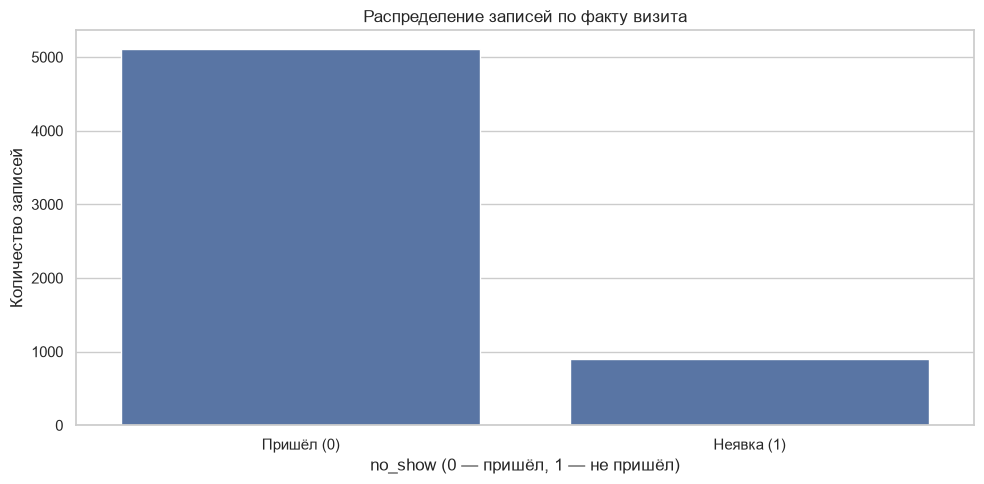

In [7]:
target_table = (
    df["no_show"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Клиент пришёл", 1: "Неявка"})
    .to_frame("Количество")
)
target_table["Доля, %"] = (
    target_table["Количество"] / len(df) * 100
).round(2)
display(target_table)

sns.countplot(data=df, x="no_show", color="C0")
plt.title("Распределение записей по факту визита")
plt.xlabel("no_show (0 — пришёл, 1 — не пришёл)")
plt.ylabel("Количество записей")
plt.xticks([0, 1], ["Пришёл (0)", "Неявка (1)"])
plt.tight_layout()
plt.show()

**Комментарий к результатам.**
Доля класса 1 показывает, насколько часто в созданном наборе встречается неявка.
Поскольку классы могут быть представлены неравномерно, одной Accuracy недостаточно:
модель, которая всегда выбирает более частый класс, может выглядеть точной, но не находить
неявки. Для оценки классификатора далее уместны Precision, Recall, Average Precision
(PR-AUC в распространённой формулировке) и ROC-AUC.

## 5. Неявки по календарю

Для сравнения групп используем долю неявок, а не только абсолютное количество:
у разных часов и дней может быть разное число записей.

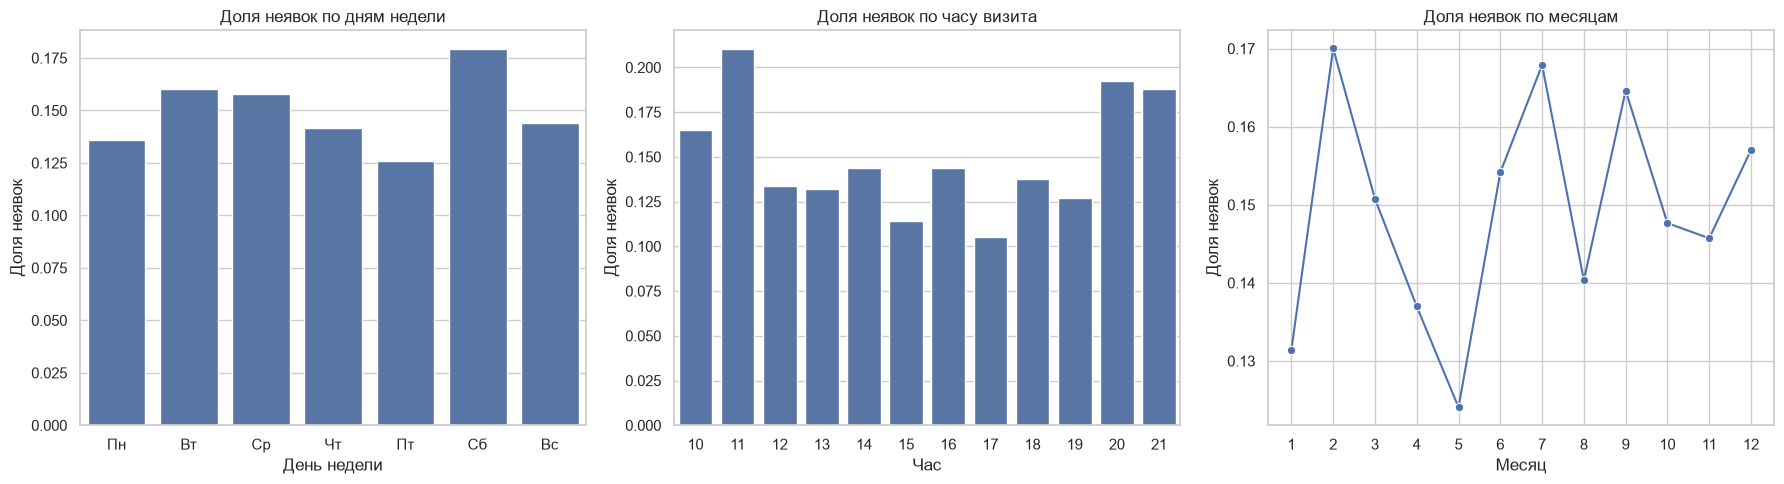

In [8]:
weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
df["weekday_name"] = df["day_of_week"].map(dict(enumerate(weekday_names)))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

weekday_rate = df.groupby("weekday_name", observed=False)["no_show"].mean()
weekday_rate = weekday_rate.reindex(weekday_names)
sns.barplot(x=weekday_rate.index, y=weekday_rate.values, ax=axes[0], color="C0")
axes[0].set_title("Доля неявок по дням недели")
axes[0].set_xlabel("День недели")
axes[0].set_ylabel("Доля неявок")

hour_rate = df.groupby("hour")["no_show"].mean()
sns.barplot(x=hour_rate.index, y=hour_rate.values, ax=axes[1], color="C0")
axes[1].set_title("Доля неявок по часу визита")
axes[1].set_xlabel("Час")
axes[1].set_ylabel("Доля неявок")

month_rate = df.groupby("month")["no_show"].mean()
sns.lineplot(x=month_rate.index, y=month_rate.values, marker="o", ax=axes[2])
axes[2].set_title("Доля неявок по месяцам")
axes[2].set_xlabel("Месяц")
axes[2].set_ylabel("Доля неявок")
axes[2].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [9]:
print("Количество записей по часам:")
display(df.groupby("hour").size().rename("Количество").to_frame())

print("Количество записей по дням недели:")
display(
    df.groupby("weekday_name").size()
      .reindex(weekday_names)
      .rename("Количество")
      .to_frame()
)

Количество записей по часам:


,Количество
hour,
10,473
11,514
12,532
13,493
14,480
15,491
16,501
17,505
18,538


Количество записей по дням недели:


,Количество
weekday_name,
Пн,905
Вт,885
Ср,861
Чт,832
Пт,827
Сб,787
Вс,903


**Комментарий к результатам.**
На графиках можно заметить возможные различия между временными группами.
Однако сами по себе колебания не доказывают устойчивую сезонность: важно проверять
размер каждой группы и подтверждать наблюдения на независимой выборке.
В дальнейшем календарные признаки можно оставить в модели и проверить их полезность
на тестовом периоде.

## 6. Профиль клиента и история посещений

Сравним распределения числовых признаков для клиентов, которые пришли, и тех, кто не пришёл.

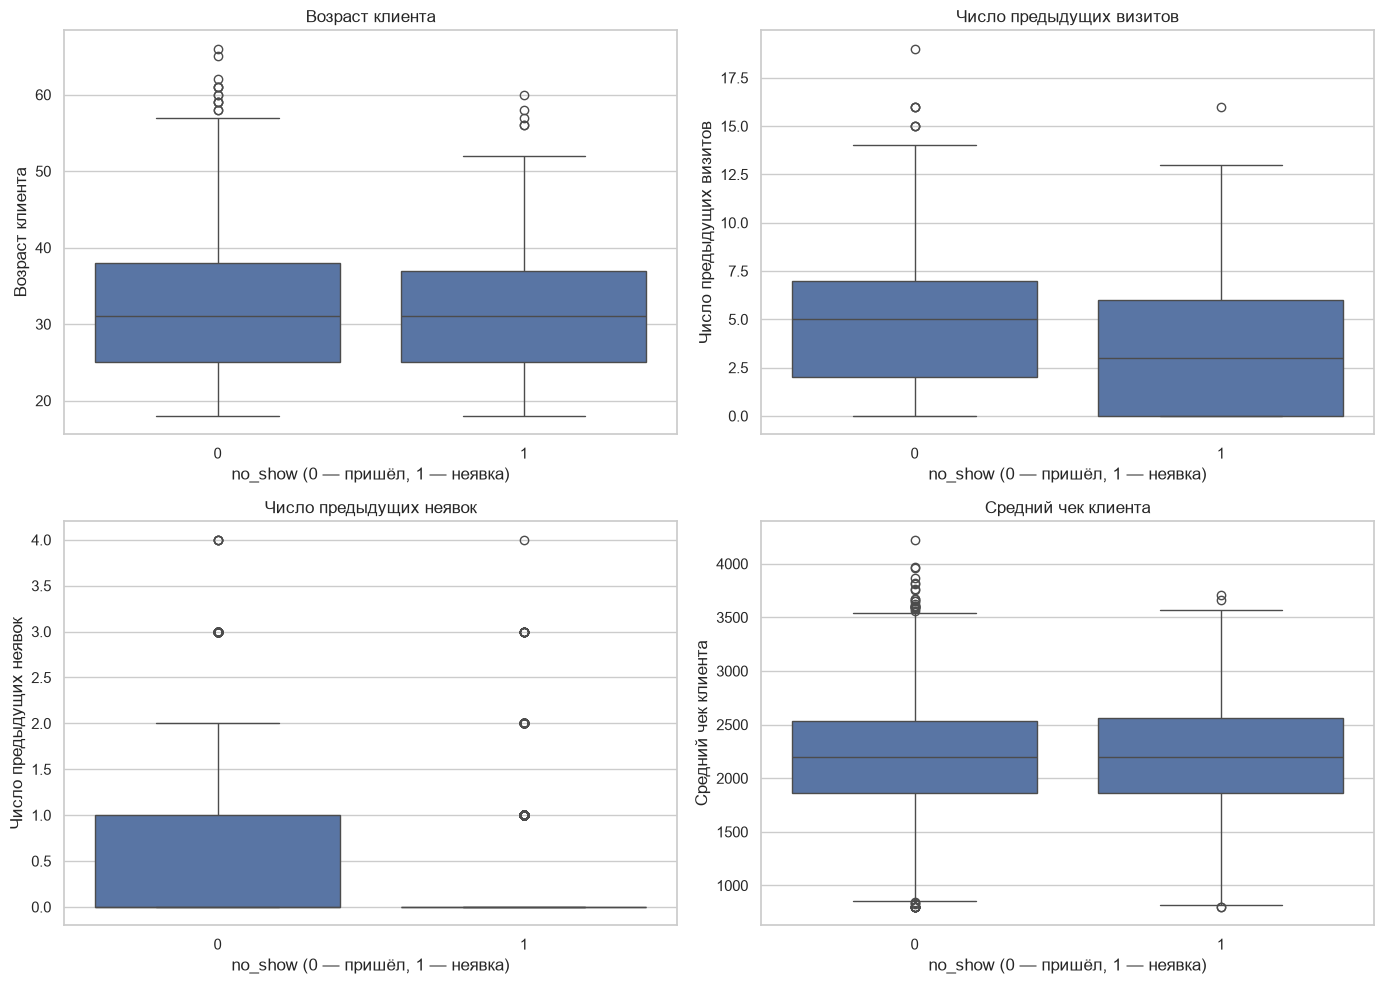

In [10]:
features_to_plot = [
    ("client_age", "Возраст клиента"),
    ("visits_total", "Число предыдущих визитов"),
    ("no_show_total", "Число предыдущих неявок"),
    ("avg_check", "Средний чек клиента"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (feature, title) in zip(axes.flat, features_to_plot):
    sns.boxplot(data=df, x="no_show", y=feature, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("no_show (0 — пришёл, 1 — неявка)")
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

In [11]:
history_rate = (
    df.assign(history_group=pd.cut(
        df["no_show_total"],
        bins=[-1, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3+"]
    ))
    .groupby("history_group", observed=False)
    .agg(
        appointments=("no_show", "size"),
        no_show_rate=("no_show", "mean")
    )
)
history_rate["no_show_rate_pct"] = (history_rate["no_show_rate"] * 100).round(2)
display(history_rate)

,appointments,no_show_rate,no_show_rate_pct
history_group,,,
0,4267,0.159831,15.98
1,1302,0.113671,11.37
2,341,0.146628,14.66
3+,90,0.155556,15.56


**Комментарий к результатам.**
Boxplot позволяет сравнить медианы, разброс и отдельные крайние значения.
Если распределения групп заметно отличаются, признак может быть полезен для модели,
но это ещё не доказывает причинную связь. История неявок особенно важна только при условии,
что она рассчитана исключительно по событиям, произошедшим до текущей записи.

## 7. Категориальные признаки

Сравним доли неявок по типу услуги, каналу записи, первому визиту и наличию напоминания.

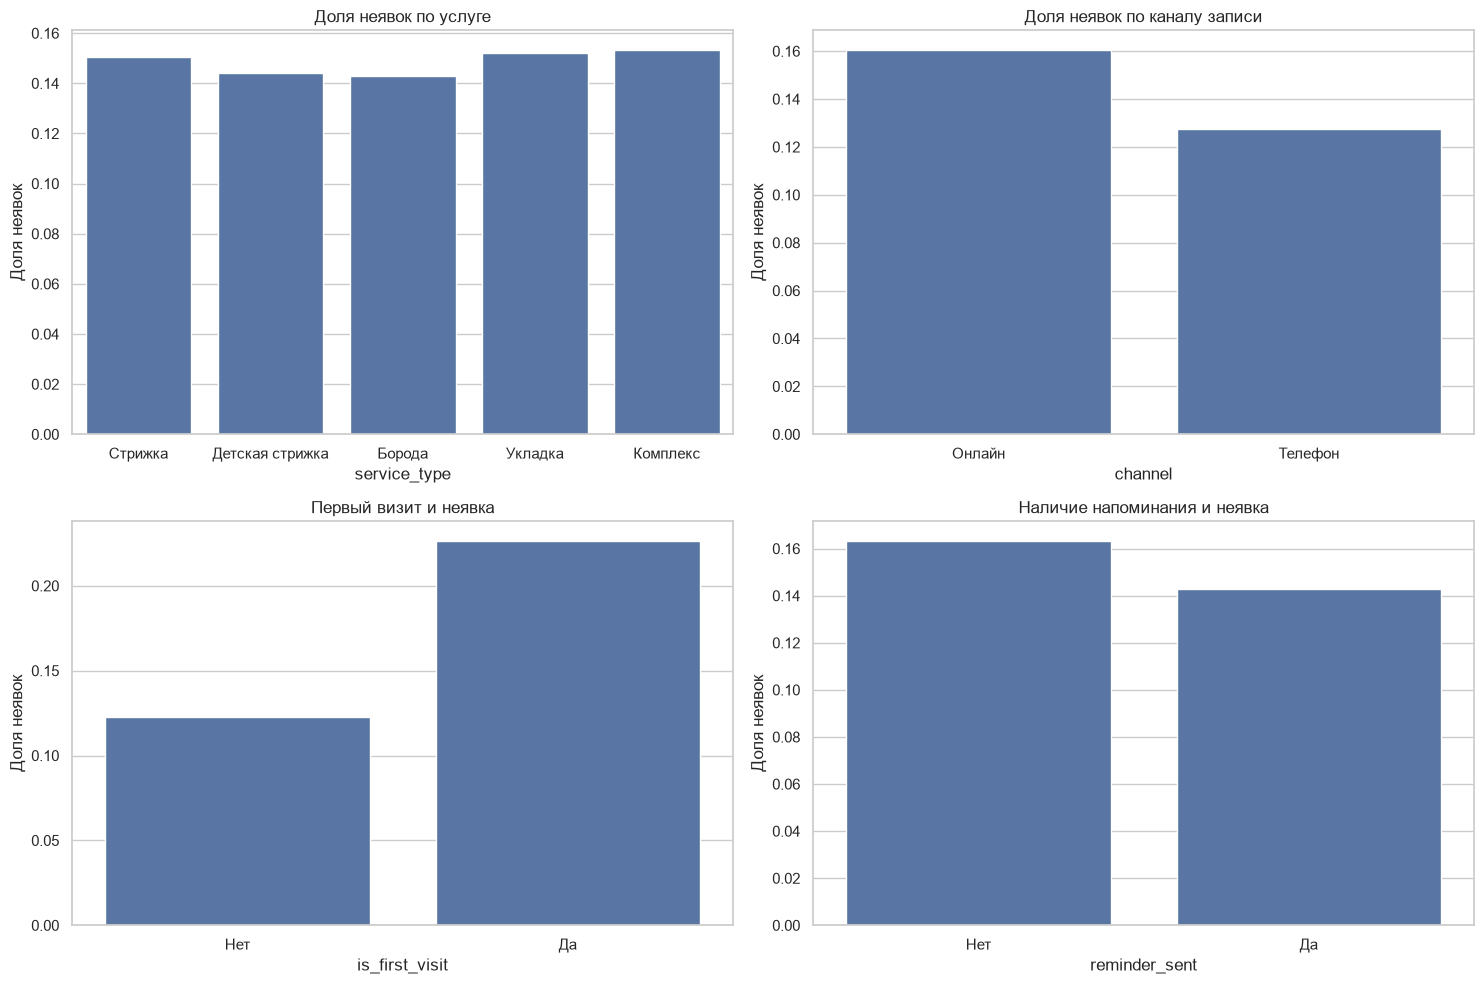

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
category_specs = [
    ("service_type", "Доля неявок по услуге"),
    ("channel", "Доля неявок по каналу записи"),
    ("is_first_visit", "Первый визит и неявка"),
    ("reminder_sent", "Наличие напоминания и неявка"),
]

for ax, (feature, title) in zip(axes.flat, category_specs):
    order = None
    if feature in ("is_first_visit", "reminder_sent"):
        order = [False, True]

    sns.barplot(
        data=df, x=feature, y="no_show",
        order=order, errorbar=None, ax=ax, color="C0"
    )
    ax.set_title(title)
    ax.set_xlabel(feature)
    ax.set_ylabel("Доля неявок")

    if feature in ("is_first_visit", "reminder_sent"):
        ax.set_xticks([0, 1], labels=["Нет", "Да"])

plt.tight_layout()
plt.show()

In [13]:
for feature in ["service_type", "channel", "is_first_visit", "reminder_sent"]:
    summary = (
        df.groupby(feature, observed=False)["no_show"]
          .agg(["count", "mean"])
          .rename(columns={"count": "Количество записей", "mean": "Доля неявок"})
    )
    summary["Доля неявок, %"] = (summary["Доля неявок"] * 100).round(2)
    print(f"\nПризнак: {feature}")
    display(summary)


Признак: service_type


,Количество записей,Доля неявок,"Доля неявок, %"
service_type,,,
Борода,1233,0.142741,14.27
Детская стрижка,596,0.144295,14.43
Комплекс,1193,0.153395,15.34
Стрижка,2682,0.150634,15.06
Укладка,296,0.152027,15.20



Признак: channel


,Количество записей,Доля неявок,"Доля неявок, %"
channel,,,
Онлайн,3904,0.160605,16.06
Телефон,2096,0.127385,12.74



Признак: is_first_visit


,Количество записей,Доля неявок,"Доля неявок, %"
is_first_visit,,,
False,4486,0.122827,12.28
True,1514,0.226552,22.66



Признак: reminder_sent


,Количество записей,Доля неявок,"Доля неявок, %"
reminder_sent,,,
False,1812,0.163355,16.34
True,4188,0.142789,14.28


Графики показывают ассоциацию признаков с целевой переменной в синтетическом наборе.
Сравнение групп с напоминанием и без него не доказывает причинный эффект напоминания:
в реальных данных напоминания могут чаще отправлять определённым категориям клиентов.
Чтобы оценить эффект, потребуется отдельный эксперимент или более аккуратный анализ.

## 8. Выбросы

Проверим распределения стоимости услуги и давности прошлого визита.
Крайнее значение не обязательно является ошибкой — сначала нужно понять его смысл.

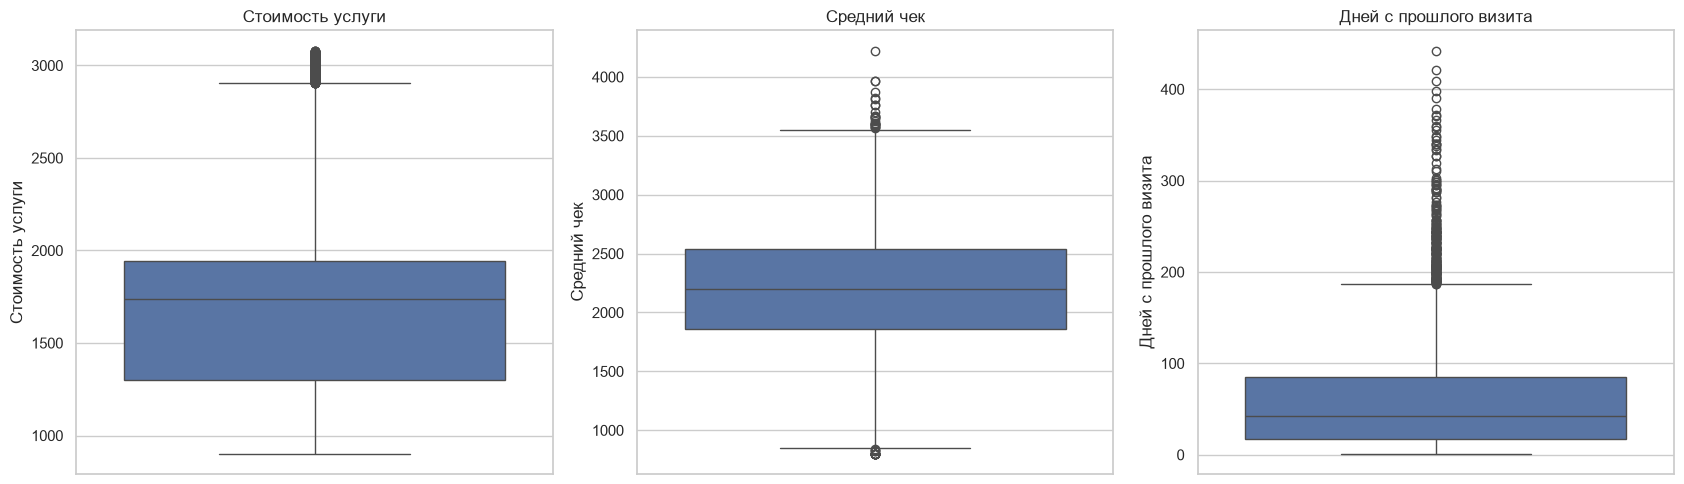

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, feature, title in zip(
    axes,
    ["price", "avg_check", "last_visit_days_ago"],
    ["Стоимость услуги", "Средний чек", "Дней с прошлого визита"],
):
    sns.boxplot(data=df, y=feature, ax=ax)
    ax.set_title(title)
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

In [15]:
display(
    df[["price", "avg_check", "last_visit_days_ago", "client_age"]]
      .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
)

,count,mean,std,min,1%,25%,50%,75%,99%,max
price,6000.0,1796.552333,574.399328,901.0,937.97,1299.000000,1739.000000,1941.000000,3045.000000,3080.000000
avg_check,6000.0,2202.902500,500.901064,800.0,1039.99,1864.000000,2201.000000,2541.000000,3401.050000,4223.000000
last_visit_days_ago,4486.0,61.376660,60.305053,1.0,1.00,17.663778,42.616354,85.283528,273.271178,442.238509
client_age,6000.0,31.575500,8.583293,18.0,18.00,25.000000,31.000000,38.000000,53.000000,66.000000


Выбросы следует проверять на правдоподобие и ошибки ввода, а не удалять автоматически.
Длинный правый хвост давности прошлого визита может отражать давно не посещавших клиентов.
При необходимости можно сравнить модели с исходным признаком и с `log1p`-преобразованием,
но преобразование нужно выбирать по результатам валидации, а не только по внешнему виду графика.

## 9. Корреляции числовых признаков

Корреляция показывает связь между признаками, но не доказывает причинность.
Идентификаторы исключаем: их числовые значения не имеют естественного количественного смысла.

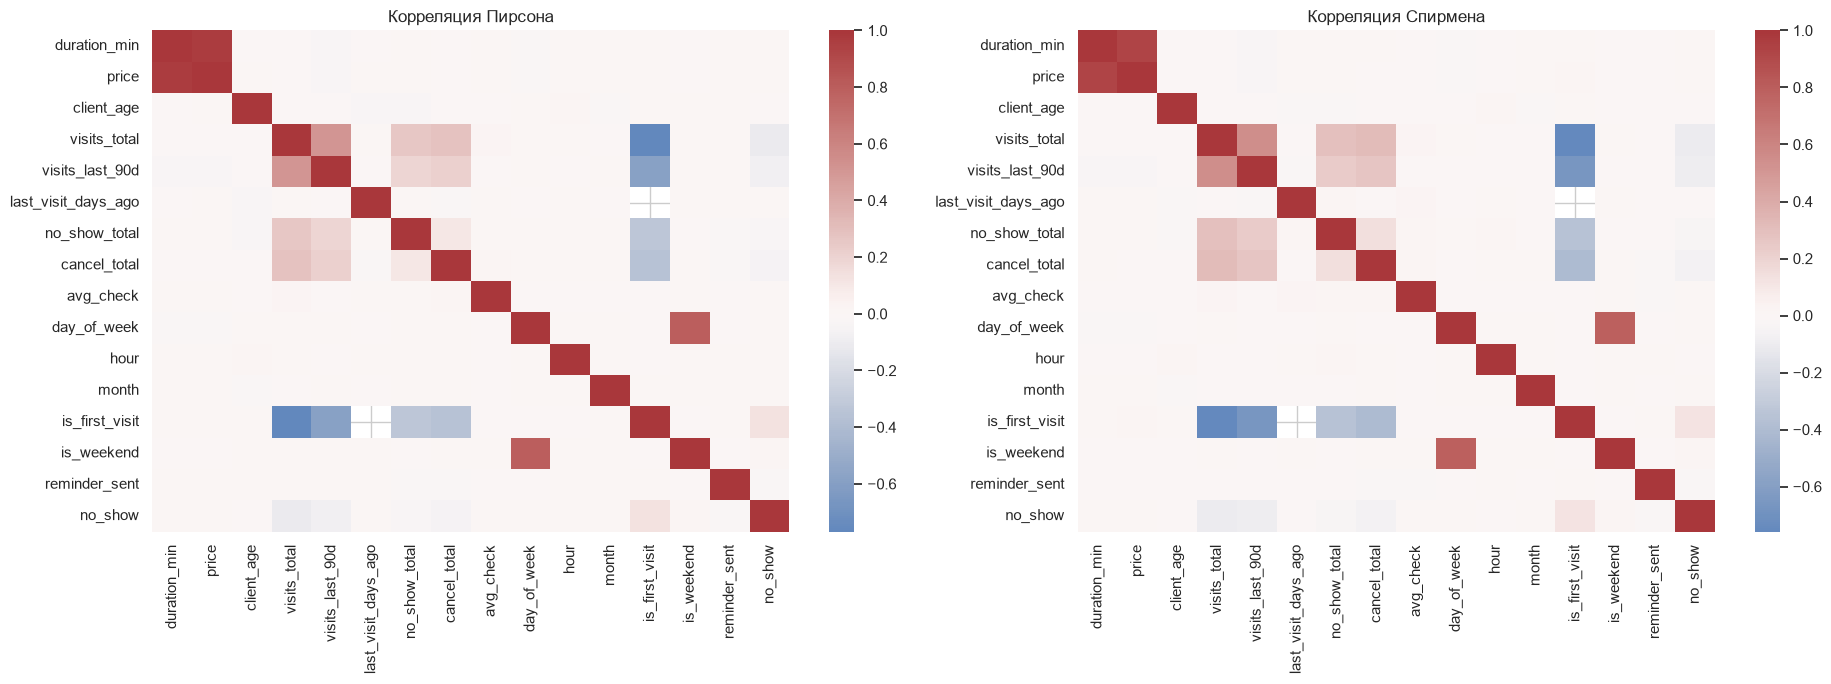

In [16]:
numeric_cols = [
    "duration_min", "price", "client_age", "visits_total",
    "visits_last_90d", "last_visit_days_ago", "no_show_total",
    "cancel_total", "avg_check", "day_of_week", "hour", "month",
    "is_first_visit", "is_weekend", "reminder_sent", "no_show"
]
corr_data = df[numeric_cols].copy()
corr_data = corr_data.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(19, 7))
sns.heatmap(
    corr_data.corr(method="pearson"),
    cmap="vlag", center=0, ax=axes[0]
)
axes[0].set_title("Корреляция Пирсона")

sns.heatmap(
    corr_data.corr(method="spearman"),
    cmap="vlag", center=0, ax=axes[1]
)
axes[1].set_title("Корреляция Спирмена")

plt.tight_layout()
plt.show()

Пирсон показывает линейную связь между числами, Спирмен —
связь по порядку (рангам). Если признаки сильно связаны между
собой, они дублируют информацию, и в модель стоит брать
только один из них.

Слабая связь с целевой переменной не значит, что признак
бесполезен — он может пригодиться в сочетании с другими.
А для категориальных признаков одной матрицы корреляции
мало, там нужны другие подходы.

## 10. Краткие итоги EDA

Ниже автоматически формируются несколько базовых фактов о созданном наборе.
Это описательная статистика синтетических данных, а не выводы о реальном бизнесе.

In [17]:
no_show_share = df["no_show"].mean() * 100
print(f"Всего записей: {len(df)}")
print(f"Доля неявок: {no_show_share:.2f}%")
print(f"Полных дубликатов: {df.duplicated().sum()}")
print(f"Пропусков всего: {int(df.isna().sum().sum())}")

print("\nДоля неявок по первому визиту:")
display(
    df.groupby("is_first_visit")["no_show"]
      .agg(["count", "mean"])
      .rename(columns={"count": "Количество", "mean": "Доля неявок"})
)

print("\nДоля неявок по каналу записи:")
display(
    df.groupby("channel")["no_show"]
      .agg(["count", "mean"])
      .rename(columns={"count": "Количество", "mean": "Доля неявок"})
)

Всего записей: 6000
Доля неявок: 14.90%
Полных дубликатов: 0
Пропусков всего: 3326

Доля неявок по первому визиту:


,Количество,Доля неявок
is_first_visit,,
False,4486,0.122827
True,1514,0.226552



Доля неявок по каналу записи:


,Количество,Доля неявок
channel,,
Онлайн,3904,0.160605
Телефон,2096,0.127385


### Выводы

1. Сформирован воспроизводимый синтетический набор записей для демонстрации EDA.
2. Целевая переменная бинарная; её фактическую долю нужно смотреть по рассчитанной таблице.
3. Временные, клиентские и категориальные признаки позволяют исследовать возможные различия
   между записями с явкой и неявкой.
4. Пропуски имеют ожидаемые причины, но перед обучением всё равно требуют обработки.
5. Корреляции и графики показывают ассоциации, а не причинно-следственные зависимости.
6. Для будущего обучения нужно исключить утечку данных, отделить тестовый период по времени
   и сравнить простую базовую модель с несколькими классификаторами.
7. Качество следует оценивать по ROC-AUC, Average Precision, Precision и Recall, а порог
   выбирать с учётом стоимости действий администратора и потерь от неявок.

**Ограничение:** выводы по синтетическим данным нельзя переносить на реальный барбершоп
без проверки на реальной CRM-выгрузке.